In [36]:
import pandas as pd

pd.set_option("display.max_columns", None)   # show all columns

device_exposure = pd.read_csv("data/Device_exposure_per_visit.csv")
measurements = pd.read_csv("data/Measurements_per_visit.csv")

/var/folders/z_/4k1gpfm969xdtxc_3z0dz3jr0000gn/T/ipykernel_3166/417182777.py:6: DtypeWarning: Columns (17: m_3004921_mode_bipap_vision_, 18: m_3004921_type_beademing_evita_4, 19: m_3004921_type_beademing_evita_1, 21: m_3004921_ventilatie_mode_set_2_, 37: m_3008223_m_emv_nice_24uur, 38: m_3008223_m_emv_nice_opname, 40: m_3009094_v_emv_nice_24uur, 41: m_3009094_v_emv_nice_opname, 66: m_3016335_e_emv_nice_24uur, 67: m_3016335_e_emv_nice_opname, 118: m_36684829_rass_score) have mixed types. Specify dtype option on import or set low_memory=False.
  measurements = pd.read_csv("data/Measurements_per_visit.csv")


In [37]:
print(device_exposure.head())

   visit_occurrence_id  device_exposure_id device_exposure_start_datetime device_exposure_end_datetime  duur_uren     visit_start_datetime       visit_end_datetime  person_id
0                    5          1437661717        2013-01-01 00:48:00 UTC      2013-01-02 20:22:00 UTC      43.57  2013-01-01 00:00:00 UTC  2013-01-03 20:27:00 UTC          5
1                   11          1437661769        2006-01-01 01:04:00 UTC      2006-01-02 12:54:00 UTC      35.83  2006-01-01 00:00:00 UTC  2006-01-02 17:17:00 UTC         11
2                   18          1437661830        2013-01-01 00:03:00 UTC      2013-01-01 07:33:00 UTC       7.50  2013-01-01 00:00:00 UTC  2013-01-01 21:26:00 UTC         17
3                   19          1437661838        2013-01-01 00:19:00 UTC      2013-01-01 16:01:00 UTC      15.70  2013-01-01 00:00:00 UTC  2013-01-03 15:58:00 UTC         18
4                   19          1437661840        2013-01-02 12:02:00 UTC      2013-01-02 19:25:00 UTC       7.38  2013-01-01

In [38]:
print(measurements.head())

   visit_occurrence_id  person_id  dag_nr       datum  uur     measurement_datetime  n_metingen  m_3000285_na_onv_ise_bloed_  m_3000285_natrium_astrup  m_3000461_asb  m_3000461_bipap_hoog  m_3000461_epap  \
0                 9142       7876      19  2013-01-19    9  2013-01-19 09:38:00 UTC          10                       140.00                       NaN            NaN                   NaN             NaN   
1                 9142       7876      19  2013-01-19   10  2013-01-19 10:28:00 UTC           8                          NaN                       NaN            NaN                   NaN             NaN   
2                 9142       7876      19  2013-01-19   11  2013-01-19 11:28:00 UTC           8                          NaN                       NaN            NaN                   NaN             NaN   
3                 9142       7876      19  2013-01-19   12  2013-01-19 12:28:00 UTC           7                          NaN                       NaN            NaN       

In [39]:
import re
item_cols = [c for c in measurements.columns if re.match(r"m_\d+_", c)]
diag = []
for c in item_cols:
    cid = int(re.match(r"m_(\d+)_", c).group(1))
    if cid in categorical_ids:
        continue
    s = pd.to_numeric(measurements[c], errors="coerce").dropna()
    if len(s):
        diag.append({"feature": names.get(cid), "item": c, "n": len(s),
                     "p1": s.quantile(.01), "median": s.median(), "p99": s.quantile(.99)})
print(pd.DataFrame(diag).sort_values(["feature", "n"]).to_string())

                  feature                                     item       n     p1  median      p99
84                abp_dia            m_21490851_abp_diastolisch_ii     297  40.84   58.00   102.80
85                abp_dia                     m_21490851_picco_apd    2319   1.00   59.00    95.82
83                abp_dia               m_21490851_abp_diastolisch  930088  37.00   60.00    99.00
87               abp_mean              m_21490852_abp_gemiddeld_ii     302   0.00   78.00   127.98
86               abp_mean                 m_21490852_abp_gemiddeld  930047  54.00   83.00   131.00
89                abp_sys             m_21490853_abp_systolisch_ii     299  74.86  125.00   196.02
90                abp_sys                     m_21490853_picco_aps    2324   1.00  122.00   197.00
88                abp_sys                m_21490853_abp_systolisch  930246  80.00  129.00   202.00
29            base_excess                           m_3012501_b_e_     482 -12.24   -2.70     7.84
30        

                                            n        min          max
3000285_na_onv_ise_bloed_              224789       0.00    11,140.00
3000285_natrium_astrup                    213     132.00     1,395.00
3000461_asb                              1712       0.00        31.00
3000461_bipap_hoog                        416       0.00        30.00
3000461_epap                               68       4.00        14.00
3000461_ps_boven_p_hoog_set_              500       0.00       446.00
3000461_ps_boven_peep_set_             518974       0.00       254.00
3000461_zephyros_p_psv                     21       3.00        30.00
3003458_fosfaat                           200       0.34       169.00
3003458_fosfaat_bloed_                  58827       0.00         7.15
3005456_k_onv_ise_bloed_               230691       0.00   260,626.00
3005456_kalium_astrup                     232       3.10       139.00
3006576_act_hco3_bloed_                270127     -24.10     2,930.00
3006576_hco3        

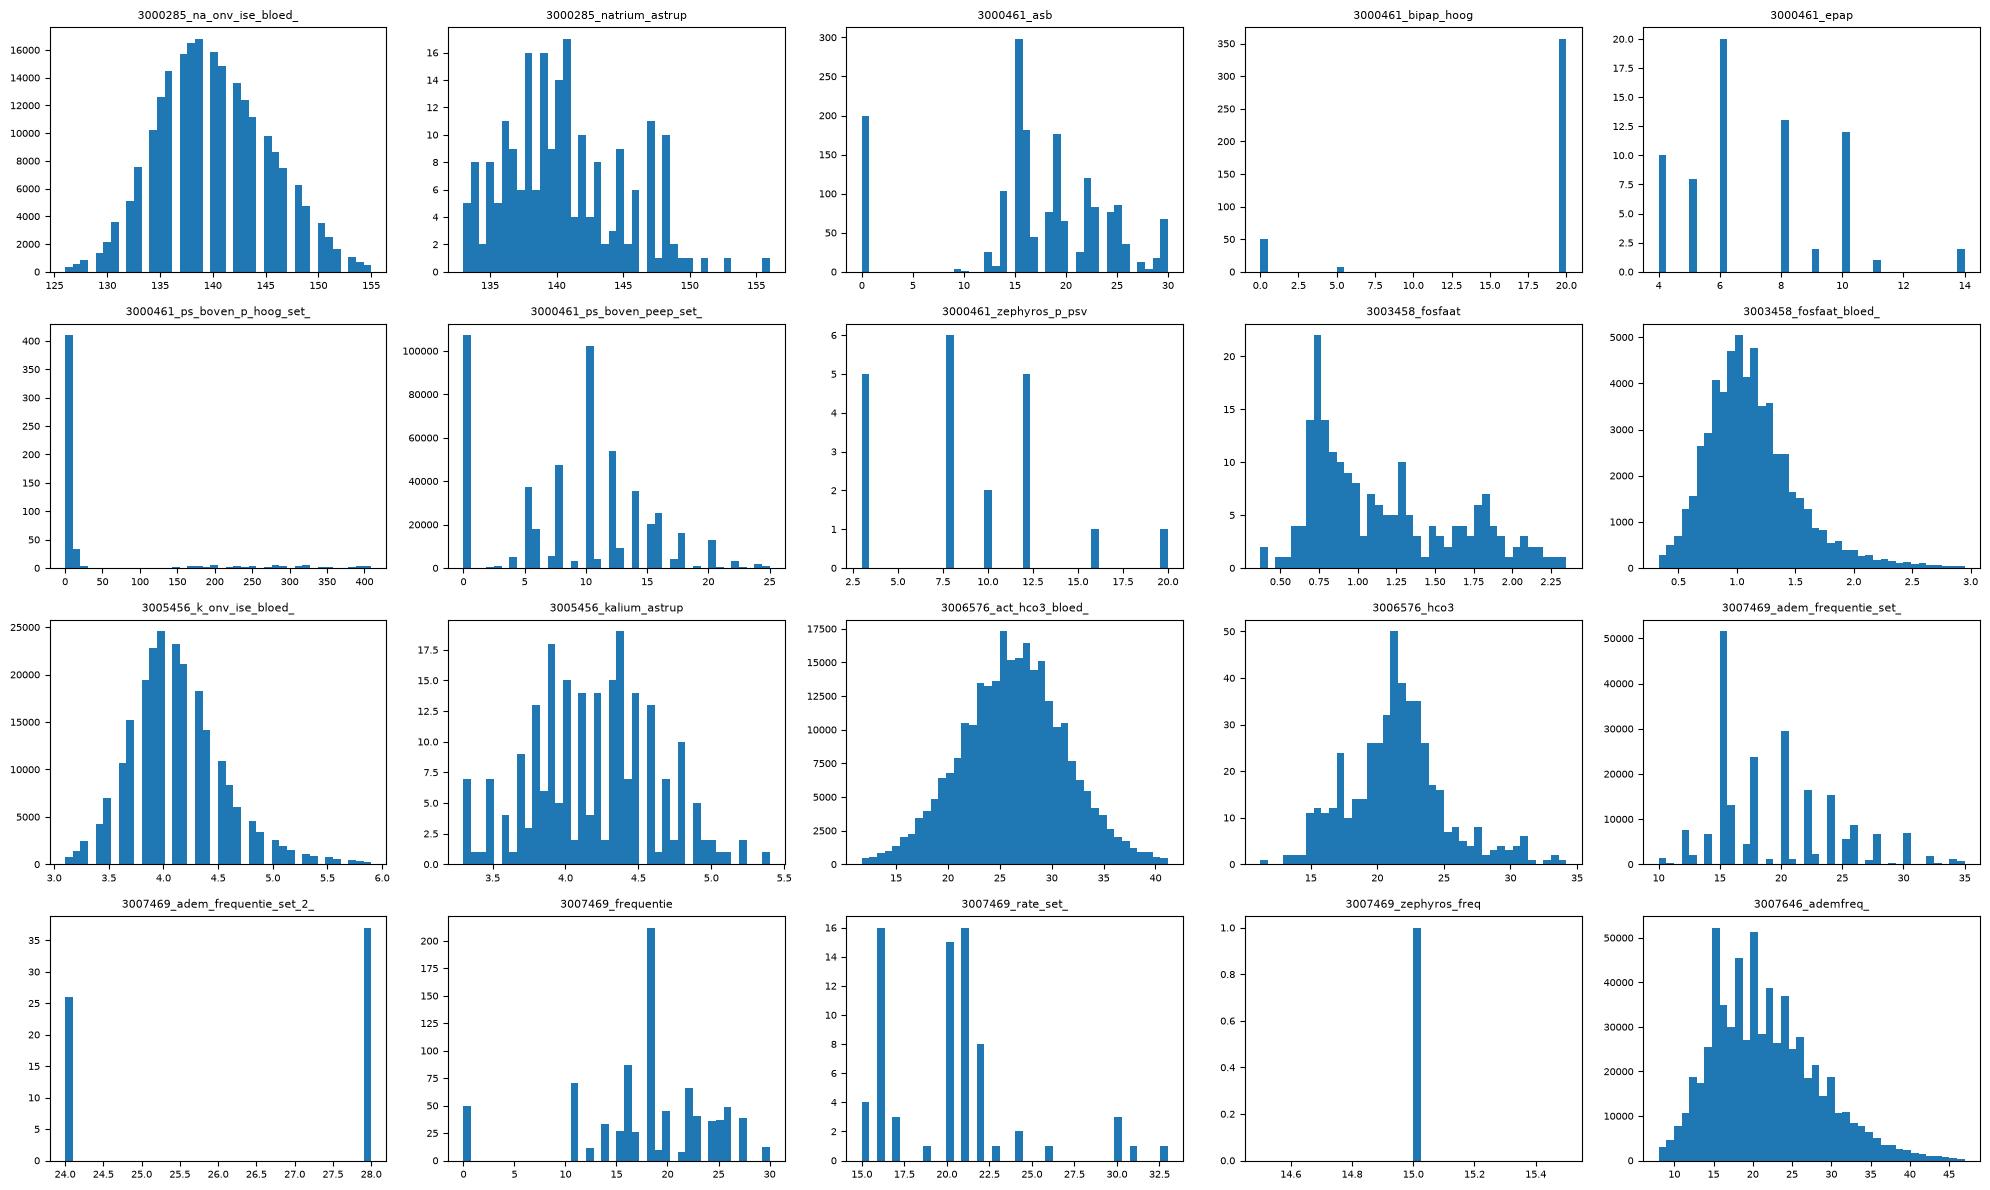

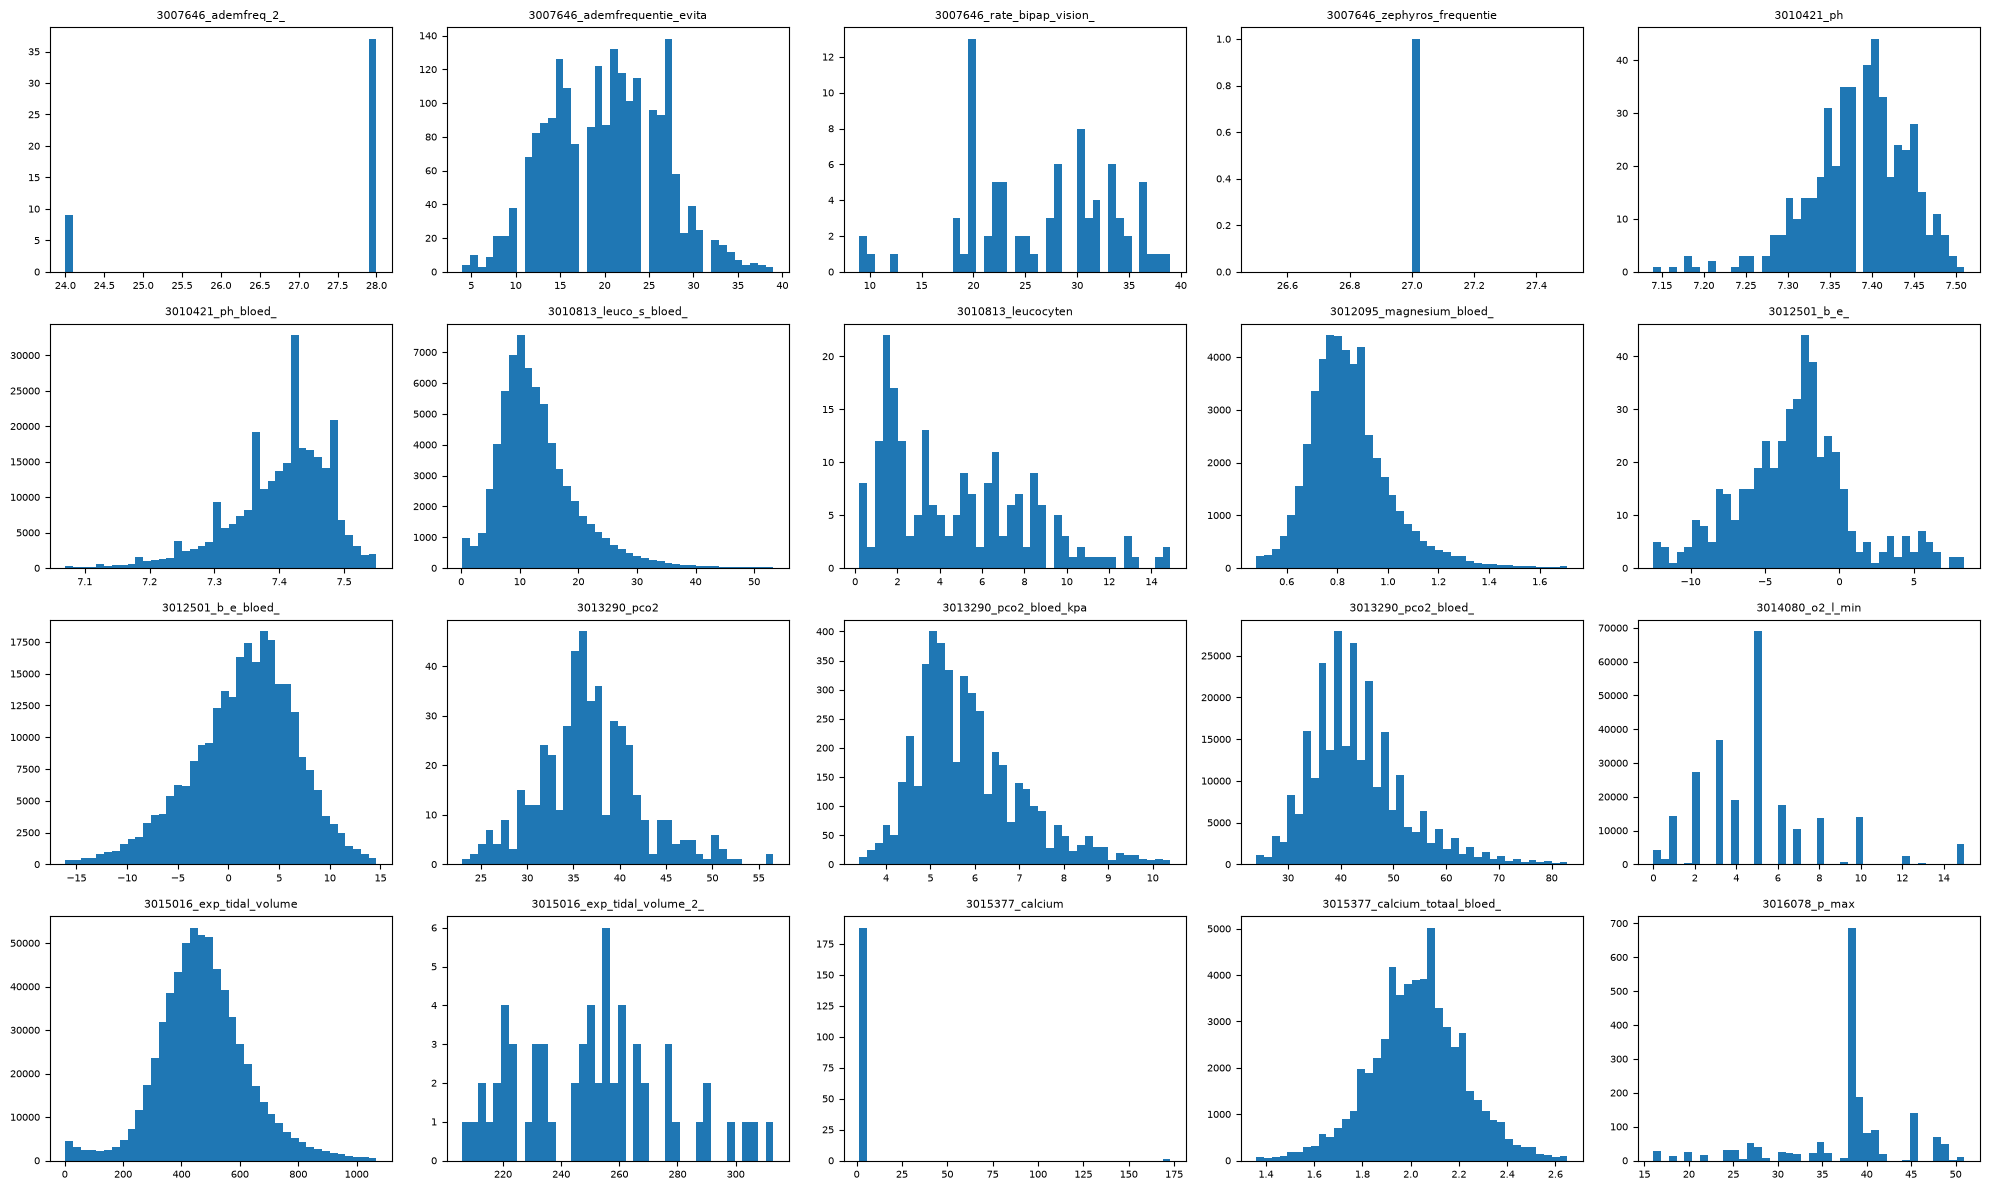

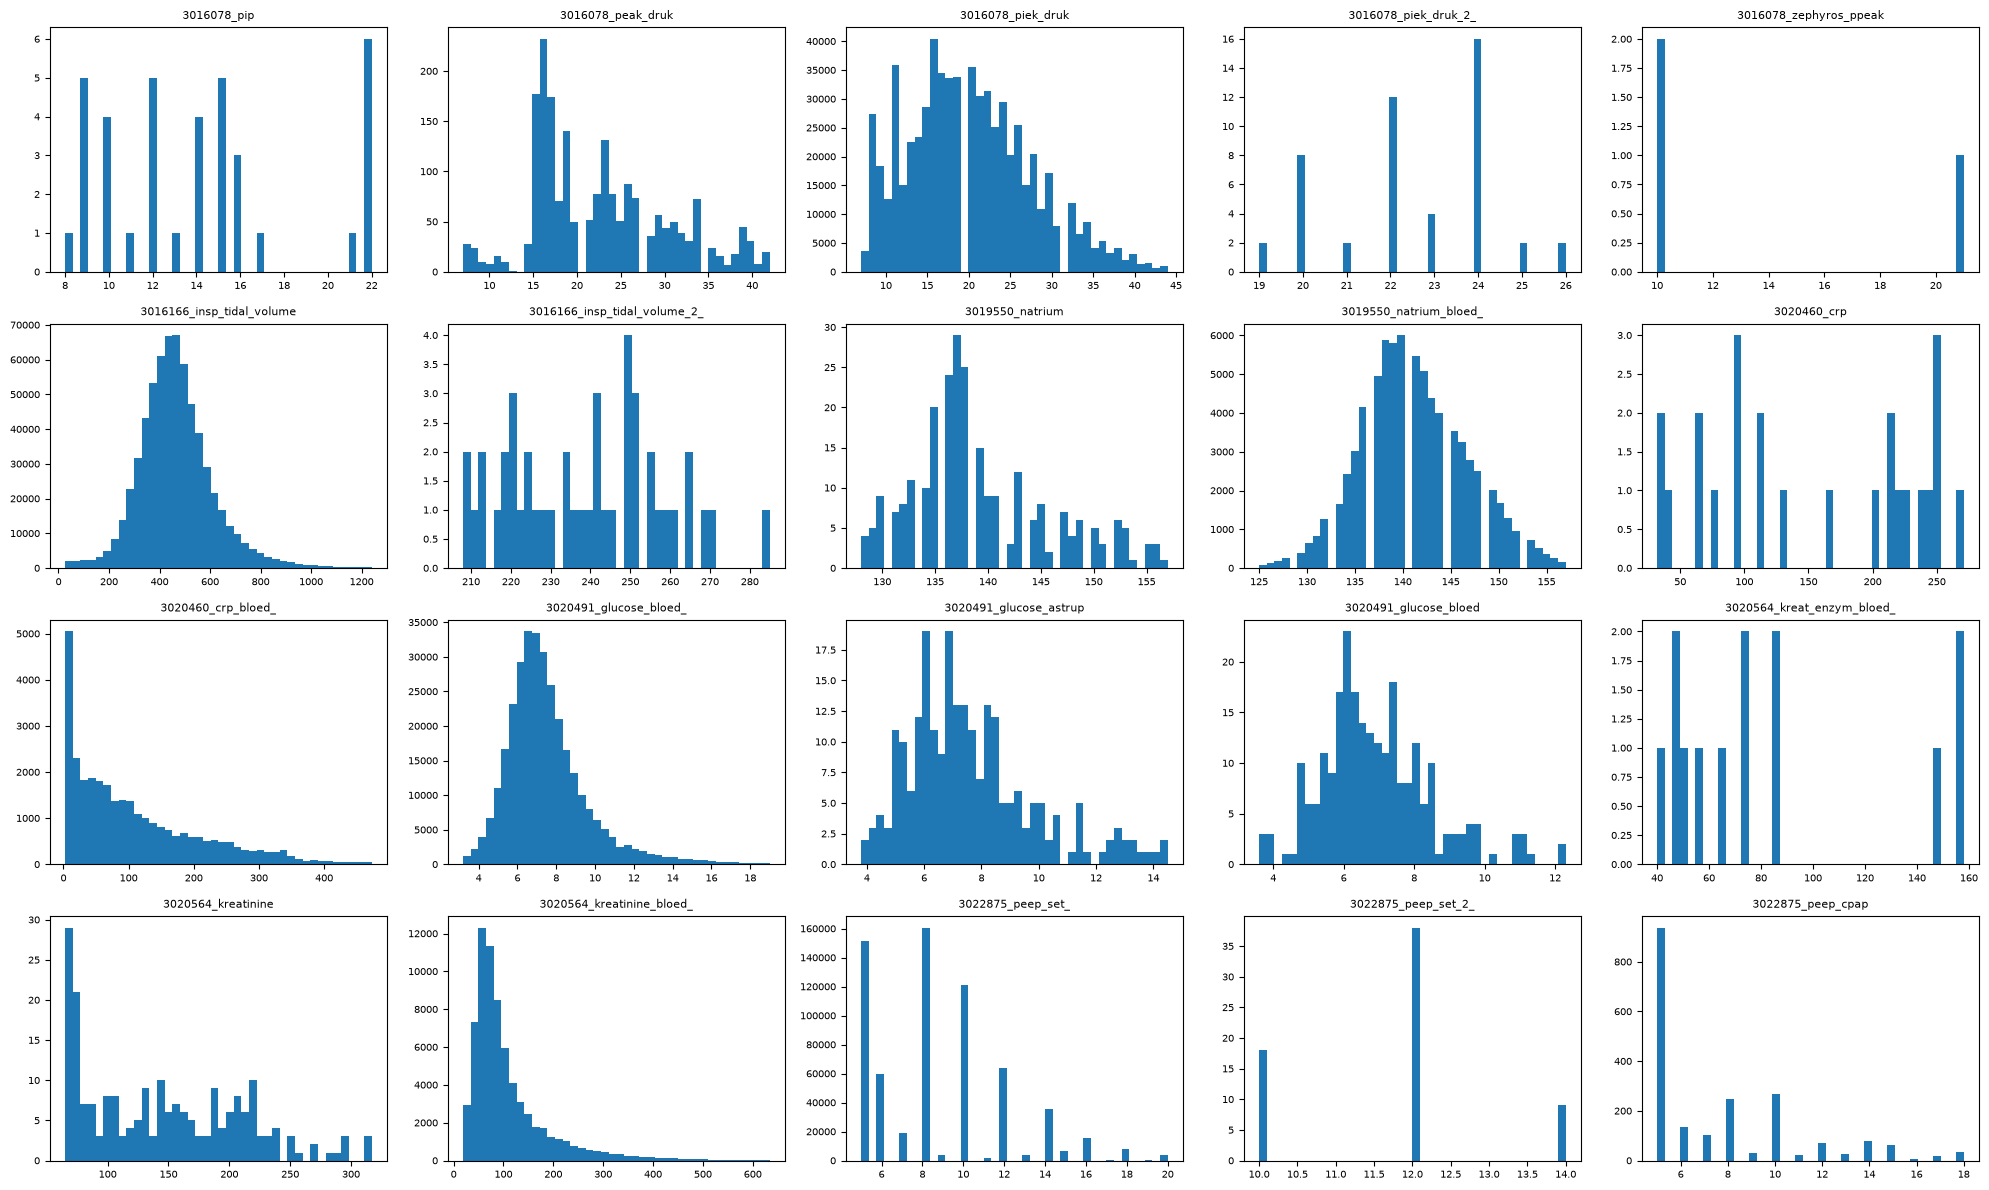

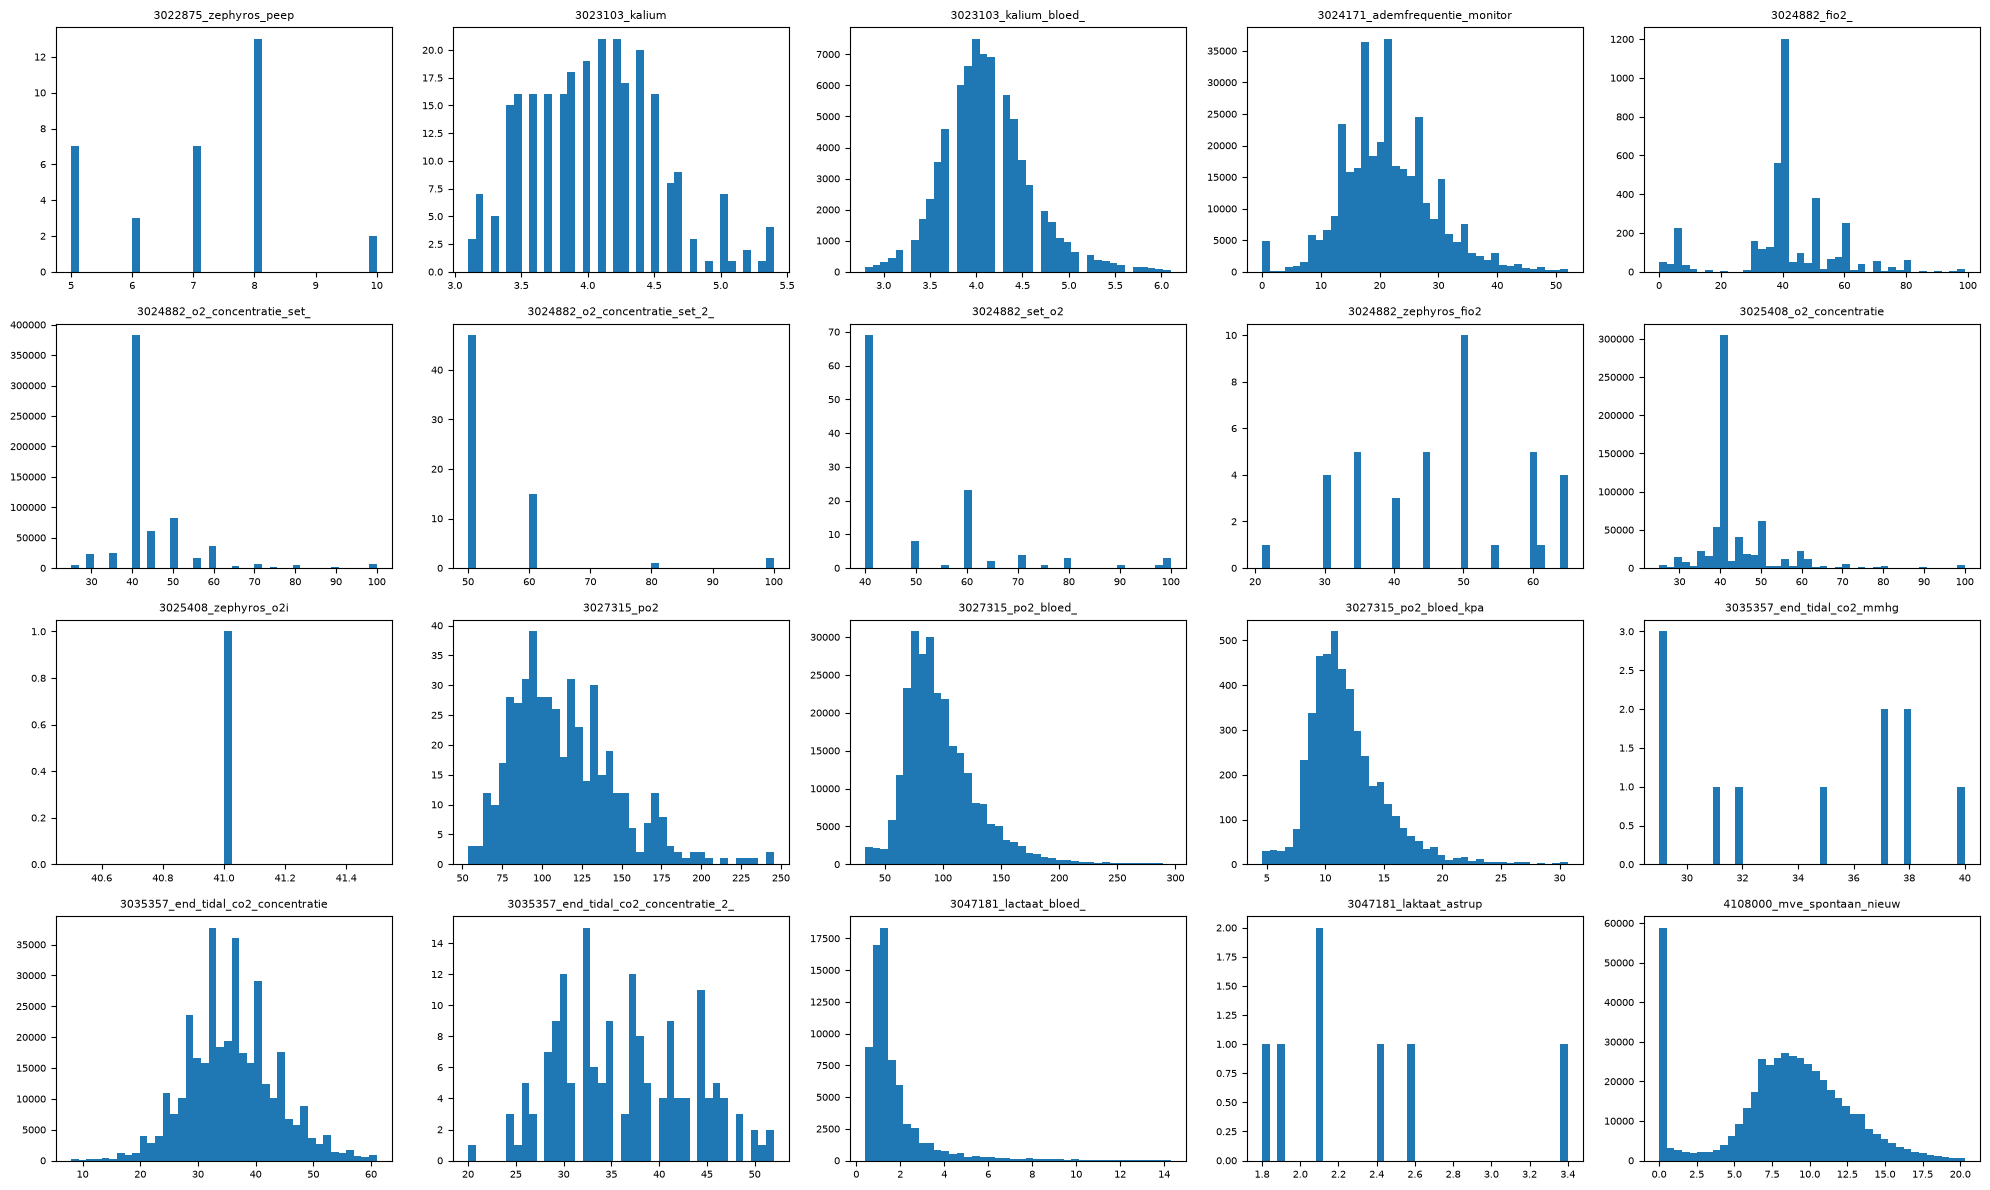

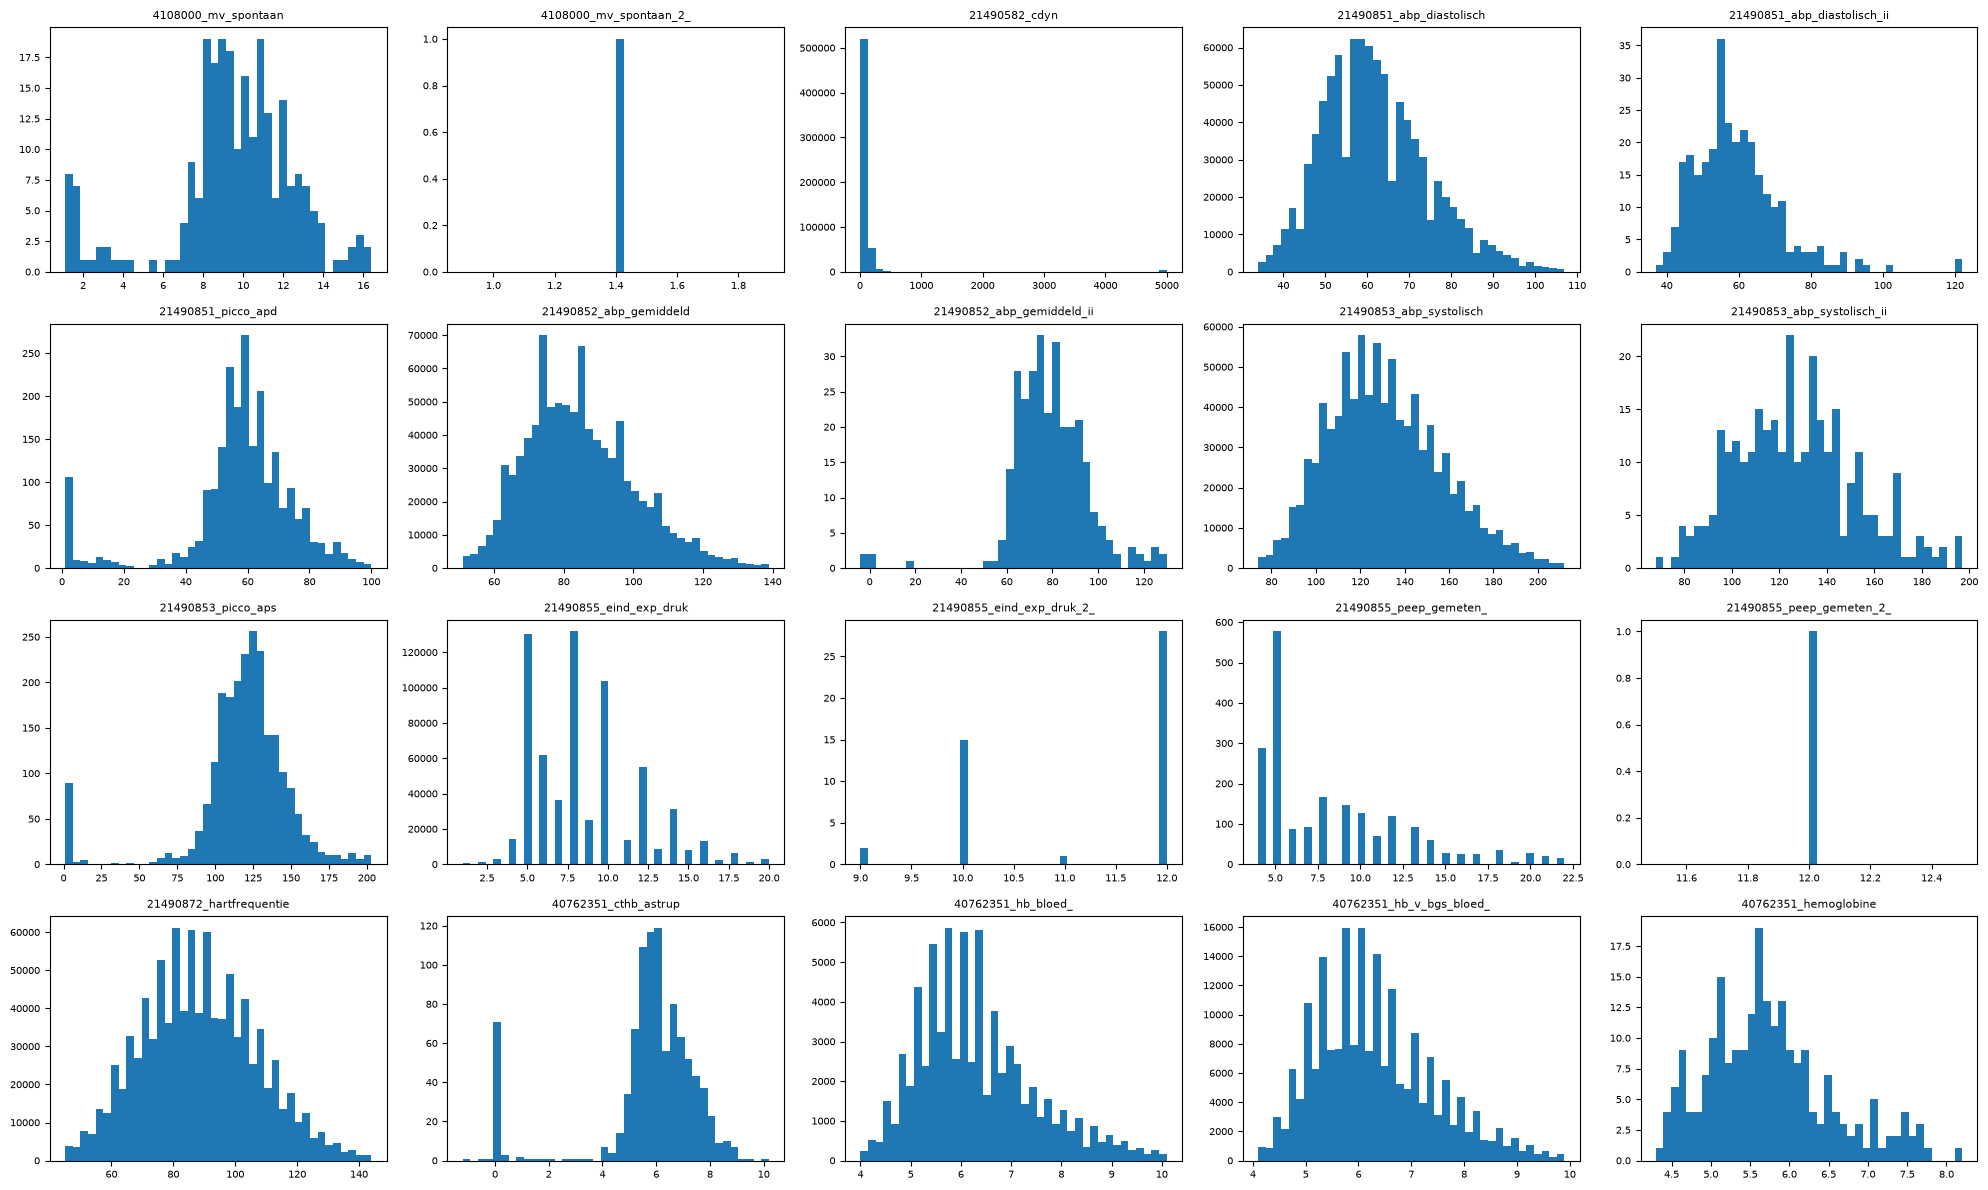

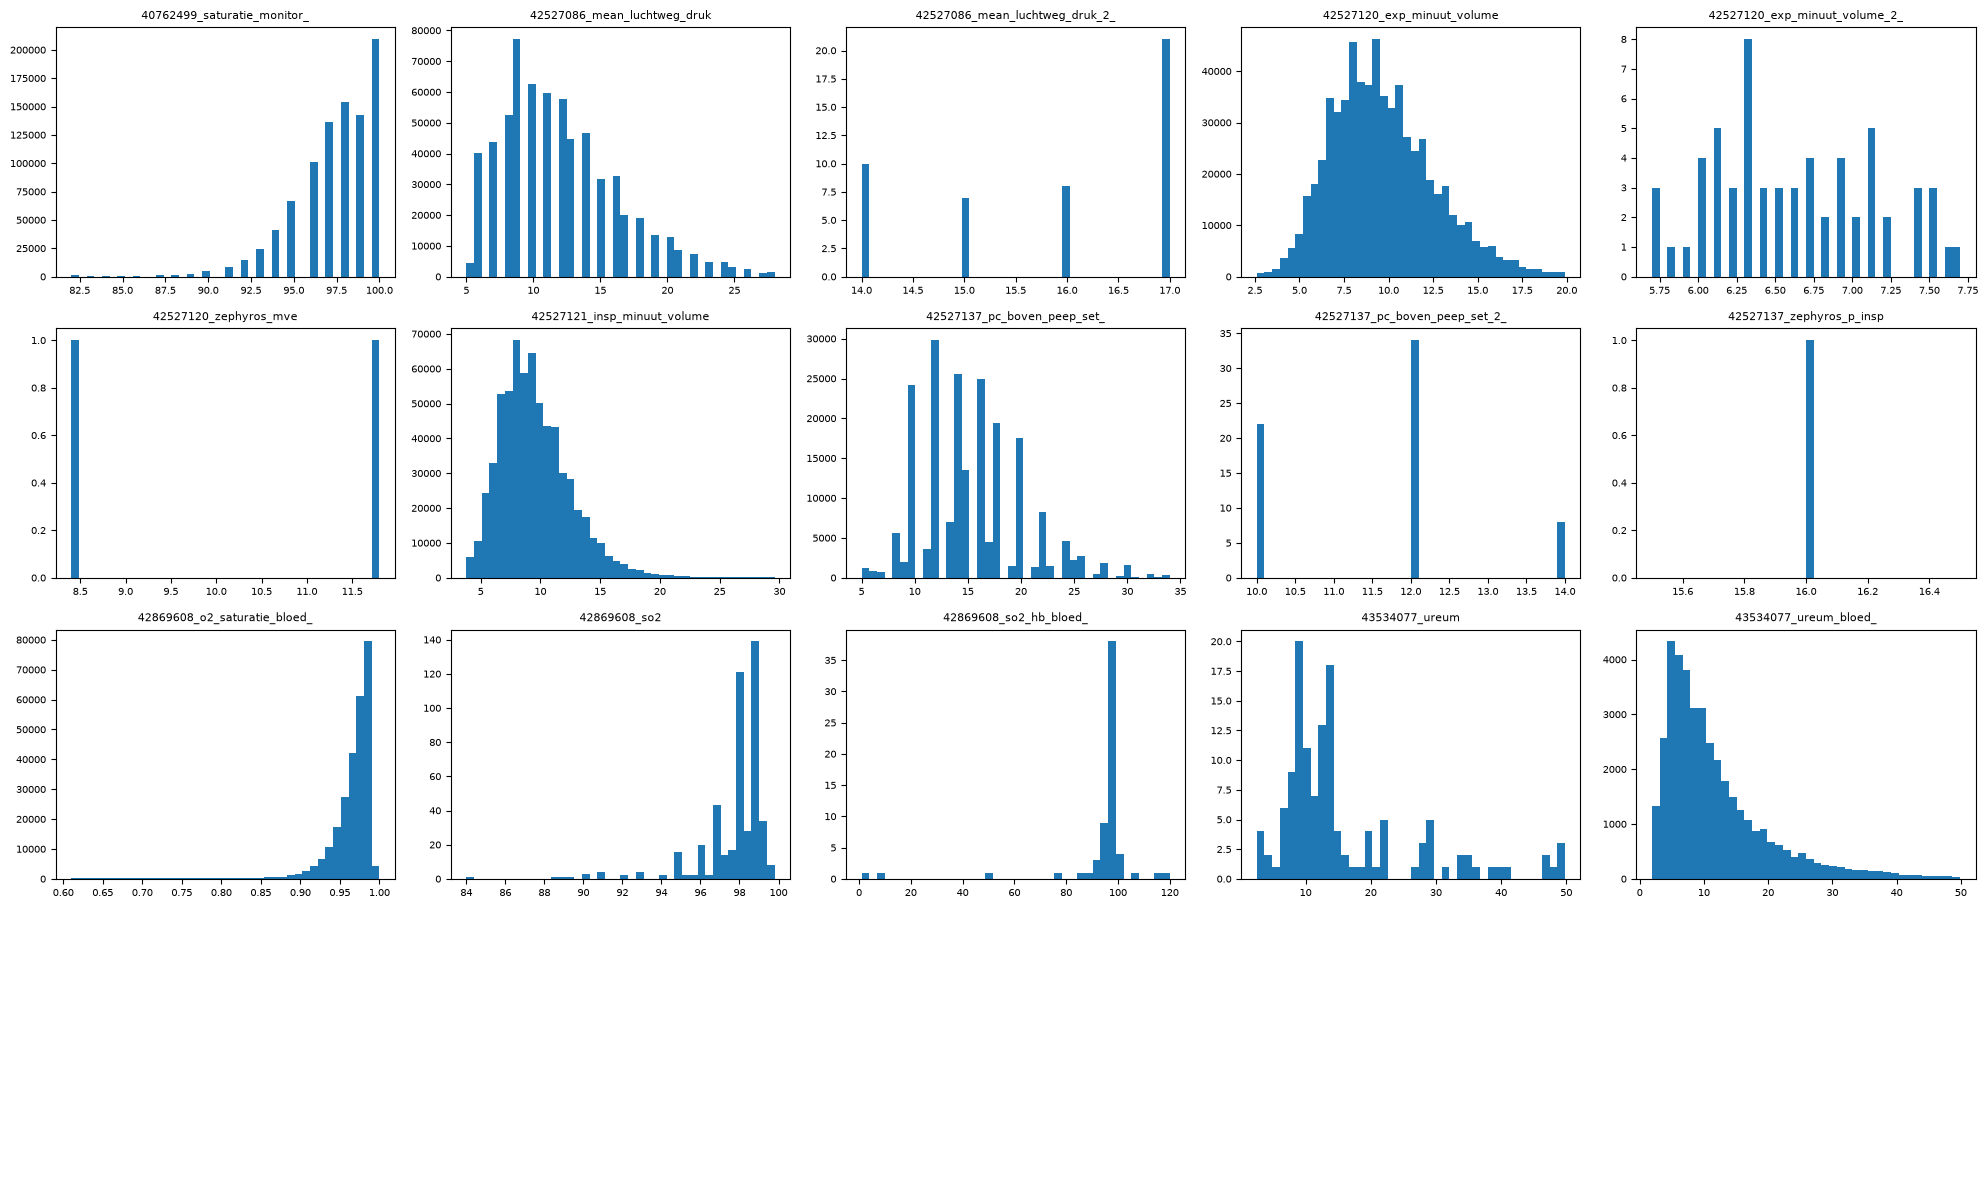

In [40]:
# raw data visualization 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = Path("data/figures_raw"); fig_dir.mkdir(parents=True, exist_ok=True)

# numeric item columns only (text columns become all-NaN and are dropped)
num_cols = [c for c in measurements.columns if c.startswith("m_")]
num = measurements[num_cols].apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")

# ---- table: n, min and max per variable ----
table = pd.DataFrame({"n": num.count(), "min": num.min(), "max": num.max()})
table.index = table.index.str.replace(r"^m_", "", regex=True)
print(table.to_string(float_format=lambda x: f"{x:,.2f}"))
table.to_csv(fig_dir / "min_max_table.csv")

# ---- histograms: 20 variables per figure ----
CLIP = True        # True: cut the 0.5% most extreme values on each side; False: full range
cols = list(num.columns)
per_page = 20
for p in range(0, len(cols), per_page):
    chunk = cols[p:p + per_page]
    fig, axes = plt.subplots(4, 5, figsize=(20, 12))
    for ax, c in zip(axes.ravel(), chunk):
        s = num[c].dropna()
        if CLIP and len(s) > 1:
            lo, hi = s.quantile([0.005, 0.995])
            s = s[(s >= lo) & (s <= hi)]
        ax.hist(s, bins=40)
        ax.set_title(c.replace("m_", "", 1)[:38], fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.ravel()[len(chunk):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(fig_dir / f"hist_raw_{p // per_page + 1}.png", dpi=120)
    plt.show()

In [41]:
# categorical data
text_concepts = {3016335, 3008223, 3009094, 3004921, 36684829, 4105091}
for c in item_cols:
    if cid_of[c] in text_concepts and "nice" not in c:
        print(f"\n=== {c} ===")
        print(measurements[c].astype("string").str.strip().value_counts(dropna=True).head(40).to_string())


=== m_3004921_mode_bipap_vision_ ===
m_3004921_mode_bipap_vision_
Assisted ventilation    72

=== m_3004921_type_beademing_evita_4 ===
m_3004921_type_beademing_evita_4
Assisted ventilation                              252
Continuous / Bi-level positive airway pressure    167
Continuous positive airway pressure                16

=== m_3004921_type_beademing_evita_1 ===
m_3004921_type_beademing_evita_1
Assisted ventilation      1259
Controlled ventilation     245

=== m_3004921_ventilatie_mode_set_ ===
m_3004921_ventilatie_mode_set_
Assisted ventilation            467940
Controlled ventilation          187733
SIMV(PC)+PS                       3253
Mandatory minute ventilation       693
Off                                102

=== m_3004921_ventilatie_mode_set_2_ ===
m_3004921_ventilatie_mode_set_2_
Controlled ventilation          73
Mandatory minute ventilation     2

=== m_3008223_beste_motore_reactie_van_de_armen ===
m_3008223_beste_motore_reactie_van_de_armen
Obeys commands          

In [42]:
# =====================================================================
# DATA CLEANING
# Input : `measurements` (wide table, one row per timestamp, columns m_<concept id>_<item name>)
# Output: `cleaned` (ids + exact time + numeric columns), saved as a CSV
# =====================================================================
import re
import numpy as np
import pandas as pd

KPA = 7.50062                       # 1 kPa = 7.50062 mmHg
PH_ID, SAO2_ID = 3010421, 42869608  # concepts that need a special unit fix

# =====================================================================
# 0. SETTINGS
# =====================================================================
# Plausible (min, max) per concept id, in the final unit. Values outside become missing.
# The text after # only says what the concept is. Provisional: confirm with a clinician.
# Concepts that are not in this dict are not used as numeric columns (e.g. cdyn 21490582).
ranges = {
    21490872: (20, 250),    # heart rate
    21490853: (20, 300),    # ABP systolic
    21490851: (10, 200),    # ABP diastolic
    21490852: (20, 220),    # ABP mean
    40762499: (40, 100),    # SpO2 (monitor)
    3024882:  (20, 100),    # FiO2 set
    3025408:  (20, 100),    # O2 concentration
    3014080:  (0, 60),      # O2 flow (L/min)
    3022875:  (0, 35),      # PEEP set
    21490855: (0, 35),      # PEEP measured
    3016078:  (3, 100),     # peak pressure
    42527086: (1, 70),      # mean airway pressure
    3000461:  (0, 40),      # pressure support
    42527137: (0, 60),      # pressure control above PEEP
    3007469:  (0, 60),      # set respiratory rate
    3007646:  (1, 80),      # respiratory rate
    3024171:  (1, 80),      # respiratory rate (monitor)
    3015016:  (20, 2000),   # expiratory tidal volume
    3016166:  (20, 2000),   # inspiratory tidal volume
    42527120: (0.5, 40),    # expiratory minute volume
    42527121: (0.5, 40),    # inspiratory minute volume
    4108000:  (0, 40),      # spontaneous minute volume
    3035357:  (5, 100),     # end-tidal CO2 (mmHg)
    3010421:  (6.6, 7.9),   # pH
    3013290:  (10, 200),    # pCO2 (mmHg)
    3027315:  (20, 700),    # pO2 (mmHg)
    3006576:  (3, 60),      # HCO3
    3012501:  (-30, 30),    # base excess
    42869608: (0.3, 1.0),   # SaO2 blood (fraction)
    40762351: (2, 15),      # haemoglobin (mmol/L)
    3010813:  (0.1, 500),   # WBC
    3020460:  (0, 800),     # CRP
    3020564:  (10, 2000),   # creatinine
    43534077: (0.5, 80),    # urea
    3019550:  (100, 180),   # sodium
    3000285:  (100, 180),   # sodium (ISE)
    3023103:  (1.5, 10),    # potassium
    3005456:  (1.5, 10),    # potassium (ISE)
    3015377:  (0.5, 4),     # calcium
    3012095:  (0.1, 5),     # magnesium
    3003458:  (0.1, 10),    # phosphate
    3020491:  (0.5, 60),    # glucose
    3047181:  (0.1, 30),    # lactate
}

# ---------------------------------------------------------------------
# Mappings for the text columns (label -> number)
# ---------------------------------------------------------------------
# Ventilation mode: 0 = controlled, 0.5 = mixed (SIMV / MMV), 1 = spontaneous / assisted
vent_mode_map = {
    "Controlled ventilation": 0,
    "SIMV(PC)+PS": 0.5,
    "Mandatory minute ventilation": 0.5,
    "Assisted ventilation": 1,
    "Continuous positive airway pressure": 1,
    "Continuous / Bi-level positive airway pressure": 1,
    # "Off" has no number: the ventilator is off, so the value stays missing
}

# Glasgow Coma Scale parts (higher = better)
gcs_eye_map = {
    "Eyes open spontaneously": 4,
    "Opens eyes in response to verbal stimulation": 3,
    "Opens eyes in response to painful stimulation": 2,
    "No eye opening": 1,
}
gcs_motor_map = {
    "Obeys commands": 6,
    "Localizing pain": 5,
    "Withdrawal from pain": 4,
    "Flexion to pain": 3,
    "Extension to pain": 2,
    "No motor response": 1,
}
gcs_verbal_map = {   # "Intubated" has no number: it carries no score, so it stays missing
    "Oriented": 5,
    "Confused": 4,
    "Inappropriate words": 3,
    "Incomprehensible sounds": 2,
    "No verbal response (>2 yrs); no vocal response (<=2 yrs)": 1,
}

# Ramsay (1 = agitated ... 6 = unresponsive; higher = deeper sedation)
ramsay_map = {
    "Agitation": 1,
    "Normal baseline for patient": 2,
    "3 wakker, alleen respons op opdracht": 3,
    "Somnolent": 4,
    "Slowness and poor responsiveness": 5,
    "Unresponsive": 6,
}

# RASS (-5 = unresponsive ... +4 = combative; higher = more agitated)
rass_map = {
    "Combative": 4,
    "Agitation": 2,
    "Restless": 1,
    "Normal baseline for patient": 0,
    "Slightly limited - Lethargic": -1,
    "Somnolent": -2,
    "Stupor": -3,
    "Pharmacologically sedated": -4,
    "Unresponsive": -5,
}

# Which mapping belongs to which item column (the column keeps its item name)
text_maps_by_item = {
    "m_3004921_mode_bipap_vision_":                 vent_mode_map,
    "m_3004921_type_beademing_evita_4":             vent_mode_map,
    "m_3004921_type_beademing_evita_1":             vent_mode_map,
    "m_3004921_ventilatie_mode_set_":               vent_mode_map,
    "m_3004921_ventilatie_mode_set_2_":             vent_mode_map,
    "m_3008223_beste_motore_reactie_van_de_armen":  gcs_motor_map,
    "m_3009094_beste_verbale_reactie":              gcs_verbal_map,
    "m_3016335_actief_openen_van_de_ogen":          gcs_eye_map,
    "m_4105091_ramsay_score":                       ramsay_map,
    "m_36684829_rass_score":                        rass_map,
}
expected_unmapped = {"Intubated", "Off"}   # labels that are meant to stay missing

# =====================================================================
# 1. CHOOSE WHICH COLUMNS WE USE
# =====================================================================
# Every measurement column is called m_<concept id>_<item name>
item_cols = [c for c in measurements.columns if re.match(r"m_\d+_", c)]
cid_of = {c: int(re.match(r"m_(\d+)_", c).group(1)) for c in item_cols}

# Columns we do NOT use:
#  - "nice" items: registry values (worst over 24 h / at admission), not real-time
#  - items with a different meaning than their concept
drop_items = {c for c in item_cols if "nice" in c} | {
    "m_3000461_bipap_hoog",            # absolute BiPAP pressure, not support above PEEP
    "m_3000461_ps_boven_p_hoog_set_",  # junk values (max 446)
    "m_3000461_epap",                  # a PEEP-type pressure (only 68 values)
    "m_3016078_p_max",                 # looks like a pressure limit setting
}

numeric_items = [c for c in item_cols if cid_of[c] in ranges and c not in drop_items]
text_items = list(text_maps_by_item)

missing_cols = [c for c in text_items if c not in measurements.columns]
assert not missing_cols, f"Text columns not found in the data: {missing_cols}"
print(f"{len(numeric_items)} numeric columns, {len(text_items)} text columns used; "
      f"{len(drop_items)} dropped")

# =====================================================================
# 2. UNIT FIXES (always BEFORE the range filter)
# =====================================================================
def fix_ph(s):
    """pH sometimes lost its decimal point: 74 / 739 / 7367 instead of 7.4 / 7.39 / 7.367.
    Divide by 10, 100 or 1000, but only if the result is a plausible pH."""
    out = s.copy()
    for div in (10, 100, 1000):
        cand = s / div
        out = out.where(~((s > 14) & cand.between(6.6, 7.9)), cand)
    return out

def rescale(col, s):
    """Bring one column to the common unit of its concept."""
    if col.endswith("_kpa"):                 # pCO2 / pO2 given in kPa -> mmHg
        return s * KPA
    if cid_of[col] == SAO2_ID:               # mostly a fraction (0.98), sometimes percent (98)
        return s.where(s <= 1.5, s / 100)
    if cid_of[col] == PH_ID:
        return fix_ph(s)
    return s

# =====================================================================
# 3. NUMERIC COLUMNS: fix units, then remove impossible values
# =====================================================================
cleaned_cols, report = {}, []
for c in numeric_items:
    lo, hi = ranges[cid_of[c]]
    s = pd.to_numeric(measurements[c], errors="coerce")   # text -> missing
    s = rescale(c, s)                                     # 1) fix the unit
    bad = s.notna() & ((s < lo) | (s > hi))               # 2) outside the plausible range?
    report.append({"item": c, "n": int(s.notna().sum()), "n_removed": int(bad.sum()),
                   "pct_removed": 100 * bad.sum() / max(int(s.notna().sum()), 1)})
    cleaned_cols[c] = s.where(~bad)                       #    impossible value -> missing

# =====================================================================
# 4. TEXT COLUMNS: label -> number (the column keeps its item name)
# =====================================================================
for col, mp in text_maps_by_item.items():
    labels = measurements[col].astype("object").str.strip()                 # remove stray spaces
    unmapped = set(labels.dropna().unique()) - set(mp) - expected_unmapped
    assert not unmapped, f"{col}: labels without a mapping: {unmapped}"    # stop on surprises
    cleaned_cols[col] = pd.to_numeric(labels.map(mp), errors="coerce")     # label -> number

# =====================================================================
# 5. ASSEMBLE THE CLEANED TABLE
# =====================================================================
cleaned = pd.DataFrame(cleaned_cols).round(4)       # removes float noise (7.4499998 -> 7.45)
feats = list(cleaned.columns)

# Keep the exact timestamp (rows are not hourly; there can be several per hour)
cleaned.insert(0, "time", pd.to_datetime(measurements["measurement_datetime"], utc=True))
cleaned.insert(0, "person_id", measurements["person_id"])
cleaned.insert(0, "visit_occurrence_id", measurements["visit_occurrence_id"])

# Drop rows where every value was removed or missing
n_before = len(cleaned)
cleaned = cleaned.dropna(subset=feats, how="all").reset_index(drop=True)
print(f"\nRows: {n_before:,} -> {len(cleaned):,} (rows without any valid value removed)")

# =====================================================================
# 6. CHECKS
# =====================================================================
report = pd.DataFrame(report).sort_values("pct_removed", ascending=False)
print("\nColumns with the most removed values (% of their values):")
print(report.head(15).round(2).to_string(index=False))
report.to_csv("data/cleaning_report_items.csv", index=False)

print("\nMapped text columns: number of values per mapped value:")
for col in text_items:
    print(f"\n{col}  ({cleaned[col].notna().sum():,} values)")
    print(cleaned[col].value_counts().sort_index().to_string())

print("\nMin / max per column after cleaning (must lie inside the plausible ranges):")
print(cleaned[feats].agg(["min", "max"]).T.round(2).to_string())

# =====================================================================
# 7. SAVE
# =====================================================================
cleaned.to_csv("data/measurements_cleaned.csv", index=False)
print("\nSaved:", cleaned.shape)      # expected: 3 id/time columns + 110 numeric + 10 text = 123

110 numeric columns, 10 text columns used; 10 dropped

Rows: 1,377,720 -> 1,366,310 (rows without any valid value removed)

Columns with the most removed values (% of their values):
                                   item      n  n_removed  pct_removed
                        m_3024882_fio2_   3793        380        10.02
                 m_40762351_cthb_astrup    951         91         9.57
               m_42869608_so2_hb_bloed_     65          5         7.69
           m_3035357_end_tidal_co2_mmhg     13          1         7.69
                   m_21490851_picco_apd   2319        131         5.65
                   m_21490853_picco_aps   2324         96         4.13
                m_3024882_zephyros_fio2     41          1         2.44
            m_21490852_abp_gemiddeld_ii    302          6         1.99
       m_3024171_ademfrequentie_monitor 345851       5217         1.51
                      m_3015377_calcium    191          2         1.05
             m_3015016_exp_tidal_volu

In [43]:
# merging the smaller concepts into the main concepts to generate less (small) features

# =====================================================================
# Input : `cleaned`, `feats`, `cid_of`   Output: `merged` (one column per concept)
# =====================================================================
DROP_GCS_VERBAL = True        # verbal GCS is "Intubated" ~65% of the time: no information
id_cols = ["visit_occurrence_id", "person_id", "time"]

# 1) Group the columns by concept id
by_concept = {}
for c in feats:
    by_concept.setdefault(cid_of[c], []).append(c)

merged = cleaned[id_cols].copy()
merge_log = []

for cid, cols in by_concept.items():
    # 2) Largest column first = the main column (it keeps its item name)
    cols = sorted(cols, key=lambda c: cleaned[c].notna().sum(), reverse=True)
    main = cols[0]
    s = cleaned[main].copy()

    # 3) Fill the gaps of the main column with the smaller columns, one by one
    for c in cols[1:]:
        other = cleaned[c]
        overlap = cleaned[main].notna() & other.notna()   # rows where both have a value
        n_filled = int((s.isna() & other.notna()).sum())  # rows this column adds
        diff = (cleaned[main] - other)[overlap].abs().median() if overlap.any() else np.nan
        merge_log.append({"concept": cid, "main_column": main, "merged_column": c,
                          "n_values": int(other.notna().sum()), "n_filled": n_filled,
                          "n_overlap": int(overlap.sum()), "median_abs_diff_in_overlap": diff})
        s = s.fillna(other)                               # the main column wins when both have a value
    merged[main] = s

# 4) Optional: leave out GCS verbal
if DROP_GCS_VERBAL:
    merged = merged.drop(columns=["m_3009094_beste_verbale_reactie"], errors="ignore")

# 5) Drop rows without any value
merged_feats = [c for c in merged.columns if c not in id_cols]
n_before = len(merged)
merged = merged.dropna(subset=merged_feats, how="all").reset_index(drop=True)
print(f"Columns: {len(feats)} -> {len(merged_feats)} | rows: {n_before:,} -> {len(merged):,}")

# =====================================================================
# CHECKS
# =====================================================================
merge_log = pd.DataFrame(merge_log)
print("\nMerged columns (n_filled = rows added to the main column; "
      "median_abs_diff_in_overlap = how much the two columns differ where both have a value):")
print(merge_log.sort_values("n_filled", ascending=False).round(3).to_string(index=False))
merge_log.to_csv("data/merge_report.csv", index=False)

print("\nShare of rows with a value per column (%):")
print((merged[merged_feats].notna().mean() * 100).round(1).sort_values().to_string())

merged.to_csv("data/measurements_merged.csv", index=False)
print("\nSaved:", merged.shape)

Columns: 120 -> 48 | rows: 1,366,310 -> 1,366,305

Merged columns (n_filled = rows added to the main column; median_abs_diff_in_overlap = how much the two columns differ where both have a value):
 concept                          main_column                           merged_column  n_values  n_filled  n_overlap  median_abs_diff_in_overlap
40762351           m_40762351_hb_v_bgs_bloed_                    m_40762351_hb_bloed_     74195     68085       6110                        0.30
 3024882       m_3024882_o2_concentratie_set_                         m_3024882_fio2_      3413      3301        112                        0.00
 3007646                  m_3007646_ademfreq_          m_3007646_ademfrequentie_evita      2061      2061          0                         NaN
 3022875                  m_3022875_peep_set_                     m_3022875_peep_cpap      2056      2055          1                        0.00
 3016078                  m_3016078_piek_druk                     m_3016078_pea

In [ ]:
# making the daily step table, using the mean over a day, for categorical data we use the last value in the step

# =====================================================================
# STEP TABLE: one row per visit and step (default = day), relative to intubation
#   step  < 0 : before intubation (-1 = the 24 h just before)
#   step >= 0 : after intubation  ( 0 = first 24 h)
# Input : `merged`, `merged_feats` (merge cell), `device_exposure` (intubation times)
# Output: `steps` (index = visit_occurrence_id, step; columns = merged_feats)
# =====================================================================
import pandas as pd

# =====================================================================
# 0. SETTINGS
# =====================================================================
STEP_H = 24            # step length in hours (24 = daily, 1 = hourly)
WINDOW_DAYS = 28       # how many days after intubation we keep
PRE_DAYS = 14        # how many days BEFORE intubation we keep (None = all; e.g. 7 = one week)
n_steps = WINDOW_DAYS * 24 // STEP_H
min_step = None if PRE_DAYS is None else -(PRE_DAYS * 24 // STEP_H)

# Ordinal scores: keep a real score (last value in the step), not a mean.
# Use .min() instead of .last() further down if you prefer "worst GCS per day".
ordinal_cols = [
    "m_3008223_beste_motore_reactie_van_de_armen",   # GCS motor
    "m_3016335_actief_openen_van_de_ogen",           # GCS eye
    "m_4105091_ramsay_score",                        # Ramsay
    "m_36684829_rass_score",                         # RASS
]
last_cols = [c for c in ordinal_cols if c in merged_feats]
mean_cols = [c for c in merged_feats if c not in last_cols]   # everything else, incl. vent mode

# =====================================================================
# 1. INDEX TIME = first intubation (device start) per visit
# =====================================================================
device_exposure["device_exposure_start_datetime"] = pd.to_datetime(
    device_exposure["device_exposure_start_datetime"], utc=True)
index_time = (device_exposure.groupby("visit_occurrence_id")["device_exposure_start_datetime"]
                             .min().rename("index_time"))

# =====================================================================
# 2. ASSIGN EVERY MEASUREMENT TO A STEP
# =====================================================================
n_visits_all = merged["visit_occurrence_id"].nunique()
d = merged.merge(index_time, left_on="visit_occurrence_id", right_index=True)   # visits without an index time drop out
print(f"Visits with measurements: {n_visits_all:,} | with an intubation time: {d['visit_occurrence_id'].nunique():,}")

# How far before intubation do the measurements go?
rel_days = (d["time"] - d["index_time"]).dt.total_seconds() / 86400
pre = -rel_days[rel_days < 0]
print(f"\nRows before intubation: {len(pre):,} in {d.loc[rel_days < 0, 'visit_occurrence_id'].nunique():,} visits")
print("Days before intubation (describe):")
print(pre.describe(percentiles=[.5, .9, .99]).round(1).to_string())

d["step"] = (d["time"] - d["index_time"]).dt.total_seconds() // (STEP_H * 3600)
d["step"] = d["step"].astype(int)                         # floor: -1 = the 24 h before intubation

n_rows_before = len(d)
keep = d["step"] < n_steps                                # end of the window after intubation
if min_step is not None:
    keep &= d["step"] >= min_step                         # start of the window before intubation
d = d[keep]
print(f"\nRows kept: {len(d):,} of {n_rows_before:,}")
# Later decision: should the window stop at extubation?

# =====================================================================
# 3. SUMMARISE PER VISIT AND STEP
# =====================================================================
d = d.sort_values(["visit_occurrence_id", "time"])      # needed so "last" is the latest value
g = d.groupby(["visit_occurrence_id", "step"])

steps = g[mean_cols].mean().join(g[last_cols].last())   # mean for continuous, last value for ordinal scores
steps = steps[merged_feats]                             # keep the original column order

# =====================================================================
# 4. CHECKS
# =====================================================================
step_idx = steps.index.get_level_values(1)
print(f"\nVisit-days: {len(steps):,} (before intubation: {(step_idx < 0).sum():,}, "
      f"after: {(step_idx >= 0).sum():,}) | visits: {steps.index.get_level_values(0).nunique():,}")

print("\nNumber of days with data per visit, after intubation (step >= 0):")
print(steps[step_idx >= 0].groupby(level=0).size().describe().round(1).to_string())

print("\nVisits per step (-14 to the end of the window; earlier negative steps left out):")
vps = steps.groupby(level=1).size()
print(vps[vps.index >= -14].to_string())

print("\n% of visit-days with a value, per column - BEFORE (step < 0) and AFTER (step >= 0) intubation:")
cov = pd.DataFrame({"before": steps[step_idx < 0].notna().mean() * 100,
                    "after":  steps[step_idx >= 0].notna().mean() * 100}).round(0)
print(cov.sort_values("after").to_string())

print("\nOrdinal columns must only contain real scores:")
for c in last_cols:
    print(c, sorted(float(v) for v in steps[c].dropna().unique()))

# =====================================================================
# 5. SAVE
# =====================================================================
steps.to_csv("data/steps_daily.csv")
print("\nSaved:", steps.shape)

Visits with measurements: 4,263 | with an intubation time: 4,263

Rows before intubation: 71,710 in 4,174 visits
Days before intubation (describe):
count   71,710.00
mean         4.10
std         10.80
min          0.00
50%          1.20
90%         10.20
99%         29.90
max        310.30

Rows kept: 1,196,183 of 1,366,305

Visit-days: 51,528 (before intubation: 12,369, after: 39,159) | visits: 4,263

Number of days with data per visit, after intubation (step >= 0):
count   4,258.00
mean        9.20
std         8.80
min         1.00
25%         2.00
50%         6.00
75%        14.00
max        28.00

Visits per step (-14 to the end of the window; earlier negative steps left out):
step
-14     349
-13     366
-12     394
-11     436
-10     458
-9      499
-8      532
-7      580
-6      665
-5      726
-4      865
-3     1025
-2     1344
-1     4130
 0     4258
 1     3567
 2     3093
 3     2718
 4     2424
 5     2187
 6     1991
 7     1784
 8     1610
 9     1472
 10    1334
 11 

In [49]:
# in 56.2% there is already ventilator values when there is no intubation yet. What are we going to do here? 

v = "m_3004921_ventilatie_mode_set_"
first_vent = merged.loc[merged[v].notna()].groupby("visit_occurrence_id")["time"].min()
chk = pd.concat([first_vent.rename("first_vent"), index_time], axis=1).dropna()
lead_h = (chk["index_time"] - chk["first_vent"]).dt.total_seconds() / 3600
print("visits with ventilator values before the intubation time:", f"{(lead_h > 0).mean():.1%}")
print(lead_h[lead_h > 0].describe(percentiles=[.5, .9]).round(1).to_string())

visits with ventilator values before the intubation time: 56.2%
count   2,391.00
mean        3.00
std        13.30
min         0.00
50%         0.40
90%         3.20
max       282.30


In [ ]:
# imputation of data. Linear fill. Categorical variables carry last value forward. 

# =====================================================================
# FILLING OF MISSING VALUES in the step table
# Input : `steps` (index: visit_occurrence_id, step)
# Output: `steps_filled` (same columns, short gaps filled)
#         `imputed_flag` (True = this value was filled, not measured)
# =====================================================================
import numpy as np
import pandas as pd

# =====================================================================
# 0. SETTINGS
# =====================================================================
MAX_GAP_DAYS = 3               # only gaps of at most this many steps are filled
CONTINUOUS_METHOD = "linear"   # "linear" (also uses the next value) or "hold" (only the last value: no look-ahead)

cols = list(steps.columns)

# Ordinal scores and ventilation mode: carry the last value forward (never interpolate between scores)
hold_cols = [c for c in ["m_3008223_beste_motore_reactie_van_de_armen",   # GCS motor
                         "m_3016335_actief_openen_van_de_ogen",           # GCS eye
                         "m_4105091_ramsay_score",                        # Ramsay
                         "m_36684829_rass_score",                         # RASS
                         "m_3004921_ventilatie_mode_set_"] if c in cols]  # vent mode

# Columns that only exist in certain ventilation modes: missing = "not applicable". Leave them alone.
mode_dep_cols = [c for c in ["m_42527137_pc_boven_peep_set_",   # pressure control above PEEP
                             "m_3000461_ps_boven_peep_set_",    # pressure support above PEEP
                             "m_3007469_adem_frequentie_set_",  # set respiratory rate
                             "m_3014080_o2_l_min",              # O2 flow
                             "m_4108000_mve_spontaan_nieuw"] if c in cols]  # spontaneous MV (probably only when breathing spontaneously)

cont_cols = [c for c in cols if c not in hold_cols + mode_dep_cols]
print(f"{len(cont_cols)} continuous, {len(hold_cols)} hold, {len(mode_dep_cols)} mode-dependent columns")

# =====================================================================
# 1. FULL GRID: every step between the first and last observed step of a visit
#    (days without any measurement are missing in `steps` and must be added first)
# =====================================================================
bounds = (steps.index.to_frame(index=False)
               .groupby("visit_occurrence_id")["step"].agg(["min", "max"]))
grid = pd.MultiIndex.from_tuples(
    [(v, s) for v, lo, hi in zip(bounds.index, bounds["min"], bounds["max"]) for s in range(lo, hi + 1)],
    names=["visit_occurrence_id", "step"])
full = steps.reindex(grid)
print(f"Rows: {len(steps):,} -> {len(full):,} ({len(full) - len(steps):,} days without any measurement added)")

# =====================================================================
# 2. CANDIDATE VALUES (before the gap-length limit is applied)
# =====================================================================
filled = full.copy()
if CONTINUOUS_METHOD == "linear":
    filled[cont_cols] = (full[cont_cols].groupby(level=0, group_keys=False)
                         .apply(lambda g: g.interpolate(limit_area="inside")))   # only between two observed values
else:
    filled[cont_cols] = full[cont_cols].groupby(level=0).ffill()
filled[hold_cols] = full[hold_cols].groupby(level=0).ffill()                       # carry the last value forward

# =====================================================================
# 3. ONLY KEEP FILLS IN SHORT GAPS (a long gap stays completely missing)
# =====================================================================
def gap_length(na, visit):
    """For every missing value: the length of the run of missing values it belongs to (0 if observed)."""
    new_visit = np.r_[True, visit[1:] != visit[:-1]]
    prev_na = np.r_[False, na[:-1]]
    run_start = na & (~prev_na | new_visit)            # a run never crosses from one visit to the next
    run_id = np.where(na, np.cumsum(run_start), 0)
    return np.where(na, np.bincount(run_id)[run_id], 0)

visit_ids = full.index.get_level_values(0).to_numpy()
for c in cont_cols + hold_cols:
    na = full[c].isna().to_numpy()
    too_long = gap_length(na, visit_ids) > MAX_GAP_DAYS
    filled.loc[too_long, c] = np.nan

# Vent mode: only fill a gap if a later value exists (never hold into days off the ventilator)
for c in ["m_3004921_ventilatie_mode_set_"]:
    has_later = full[c].groupby(level=0).bfill().notna()
    filled[c] = filled[c].where(has_later | full[c].notna())

imputed_flag = filled.notna() & full.isna()            # True = filled, not measured

# =====================================================================
# 4. DROP EMPTY ROWS BEFORE INTUBATION (rows from step 0 on always stay: the time series must be continuous)
# =====================================================================
step_vals = filled.index.get_level_values(1)
keep = (filled.notna().any(axis=1) | (step_vals >= 0)).to_numpy()
steps_filled, imputed_flag = filled[keep], imputed_flag[keep]
print(f"Rows kept: {len(steps_filled):,} (empty pre-intubation rows removed: {(~keep).sum():,})")

# =====================================================================
# 5. CHECKS
# =====================================================================
cov = pd.DataFrame({"observed %": full[keep].notna().mean() * 100,
                    "after fill %": steps_filled.notna().mean() * 100}).round(1)
cov["added"] = (cov["after fill %"] - cov["observed %"]).round(1)
print("\nCoverage per column (% of rows with a value):")
print(cov.sort_values("added", ascending=False).to_string())

after = steps_filled[step_vals[keep] >= 0]
print(f"\nRows from step 0 on that are still completely empty: {int(after.isna().all(axis=1).sum()):,}")

print("\nScores must still be real scores:")
for c in [c for c in hold_cols if "ventilatie_mode" not in c]:
    print(c, sorted(float(v) for v in steps_filled[c].dropna().unique()))

# =====================================================================
# 6. SAVE
# =====================================================================
steps_filled.to_csv("data/steps_filled.csv")
imputed_flag.astype(np.int8).to_csv("data/steps_imputed_flag.csv")
print("\nSaved:", steps_filled.shape)

38 continuous, 5 hold, 5 mode-dependent columns
Rows: 51,528 -> 55,645 (4,117 days without any measurement added)
Rows kept: 53,270 (empty pre-intubation rows removed: 2,375)

Coverage per column (% of rows with a value):
                                             observed %  after fill %  added
m_3020460_crp_bloed_                              48.00         72.10  24.10
m_3012095_magnesium_bloed_                        53.30         74.30  21.00
m_43534077_ureum_bloed_                           51.10         62.30  11.20
m_3016335_actief_openen_van_de_ogen               37.30         47.00   9.70
m_4105091_ramsay_score                            30.80         40.30   9.50
m_3008223_beste_motore_reactie_van_de_armen       36.40         45.90   9.50
m_3015377_calcium_totaal_bloed_                   69.90         77.50   7.60
m_3003458_fosfaat_bloed_                          69.60         76.60   7.00
m_3024171_ademfrequentie_monitor                  45.60         51.20   5.60
m_302310